In [1]:
import matplotlib.pyplot as plt
from tbparse import SummaryReader
import pandas as pd
import numpy as np
import glob


epochs = 70
epoch_range = range(epochs)

# Overall 
df_all = pd.DataFrame({'step': epoch_range})

# Get list of run file paths
log_dir = glob.glob("runs/**/*.XY_Lenovo", recursive=True)

counter = 1

for runs in log_dir:
    reader = SummaryReader(runs, pivot=True)

    # Read all scalar logs (e.g., loss, accuracy)
    df = reader.scalars

    # Append loss and accuracy
    df_all['loss'+str(counter)], df_all['accuracy'+str(counter)] = [df["dataESC/trainingLoss"+str(counter)], df["dataESC/valLoss"+str(counter)]]

    counter +=1


print(df_all)

    step     loss1  accuracy1     loss2  accuracy2     loss3  accuracy3  \
0      0  2.137372      75.00  2.114262      72.00  2.134666      78.75   
1      1  0.465114      82.00  0.472104      79.00  0.441180      83.50   
2      2  0.177696      83.75  0.198959      82.50  0.210471      82.00   
3      3  0.136164      84.00  0.107729      78.25  0.157664      83.00   
4      4  0.098918      87.00  0.098701      80.00  0.087707      85.50   
..   ...       ...        ...       ...        ...       ...        ...   
65    65  0.002628      88.50  0.003147      89.00  0.002399      90.25   
66    66  0.002000      87.50  0.002117      88.50  0.002480      89.50   
67    67  0.002518      89.00  0.002591      89.00  0.002341      90.00   
68    68  0.002190      88.00  0.003643      89.50  0.002525      90.00   
69    69  0.002209      88.50  0.002498      88.25  0.002046      90.25   

       loss4  accuracy4     loss5  accuracy5  
0   2.193799      76.25  2.163899      73.25  
1   0

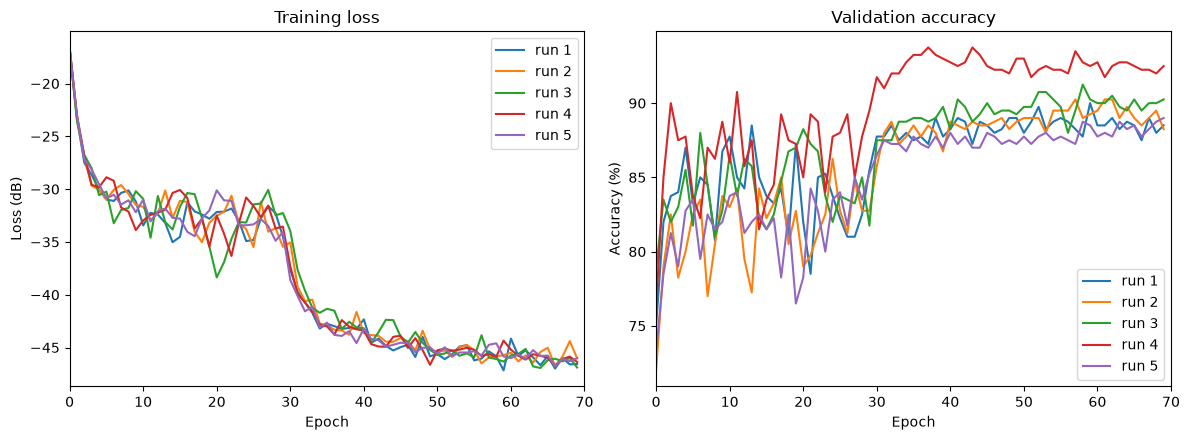

In [2]:
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4.5))

for i in range(1, counter):
    ax_loss.plot(
        epoch_range, 10*np.log10(df_all['loss'+str(i)])-20, label=f"run {i}"
    )
    ax_acc.plot(
        epoch_range, df_all['accuracy'+str(i)], label=f"run {i}"
    )

ax_loss.set_title("Training loss")
ax_loss.set_ylabel("Loss (dB)")

ax_acc.set_title("Validation accuracy")
ax_acc.set_ylabel("Accuracy (%)")

for ax in (ax_loss, ax_acc):
    ax.set_xlabel("Epoch")
    ax.set_xlim(0, 70)
    ax.legend()


fig.tight_layout()
plt.show()

In [3]:
final_loss = np.zeros(counter-1)
max = np.zeros(counter-1)
for i in range(1, counter):
    max[i-1] = df_all['accuracy'+str(i)].max()
    final_loss[i-1] = df_all['loss'+str(i)][epochs-1]

data = {
    "Run #": range(1, counter),
    "Highest Accuracy (%)": max,
    "Final Loss (%)": final_loss
}
df = pd.DataFrame(data)
display(df.style.hide(axis="index"))

Run #,Highest Accuracy (%),Final Loss (%)
1,90.000000,0.002209
2,90.250000,0.002498
3,91.250000,0.002046
4,93.750000,0.002307
5,89.000000,0.002509
